# Proyecto 5

**Como analista de datos del operador de telecomunicaciones Megaline, se plantea un ejercicio desde el departamento comercial, identificar cual es la tarifa prepago que genera más ingresos, este análisis se realiza para determinar un ajuste al presupuesto de publicidad. Se seleccionarán 500 clientes para el respectivo análisis.**

El plan de trabajo es el siguiente:

1. Cargar los cinco conjuntos de datos (tarifas, usuarios, llamadas, mensajes e internet) y estudiar su estructura general.
2. Preparar los datos: corregir tipos de datos, buscar y tratar valores ausentes, duplicados o inconsistencias.
3. Agregar la información por usuario y por mes (número de llamadas, minutos, mensajes y MB usados) y calcular el ingreso mensual de cada usuario según las condiciones de su tarifa.
4. Analizar estadísticamente el comportamiento de los usuarios de cada tarifa (media, varianza, desviación estándar, histogramas) para las llamadas, los mensajes y el uso de datos.
5. Probar dos hipótesis estadísticas: si el ingreso promedio difiere entre las tarifas Surf y Ultimate, y si el ingreso promedio de los usuarios del área Nueva York-Nueva Jersey difiere del resto.
6. Redactar una conclusión general con los hallazgos más importantes.


## ¿Cuál es la mejor tarifa?

Trabajas como analista para el operador de telecomunicaciones Megaline. La empresa ofrece a sus clientes dos tarifas de prepago, Surf y Ultimate. El departamento comercial quiere saber cuál de las tarifas genera más ingresos para poder ajustar el presupuesto de publicidad.

Vas a realizar un análisis preliminar de las tarifas basado en una selección de clientes relativamente pequeña. Tendrás los datos de 500 clientes de Megaline: quiénes son los clientes, de dónde son, qué tarifa usan, así como la cantidad de llamadas que hicieron y los mensajes de texto que enviaron en 2018. Tu trabajo es analizar el comportamiento de los clientes y determinar qué tarifa de prepago genera más ingresos.


## Inicialización


In [1]:
# cargar librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
from scipy import stats as st

## Cargar datos


In [2]:
# cada archivo se carga en un df distinto
mg_calls = pd.read_csv("megaline_calls.csv")
mg_internet = pd.read_csv("megaline_internet.csv")
mg_messages = pd.read_csv("megaline_messages.csv")
mg_plans = pd.read_csv("megaline_plans.csv")
mg_users = pd.read_csv("megaline_users.csv")

### Preparar los datos


In [3]:
# mostrar información de cada uno de los df cargados
mg_calls.info()

<class 'pandas.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  str    
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  str    
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 6.5 MB


In [4]:
mg_internet.info()

<class 'pandas.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  str    
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  str    
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 5.0 MB


In [5]:
mg_messages.info()

<class 'pandas.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   id            76051 non-null  str  
 1   user_id       76051 non-null  int64
 2   message_date  76051 non-null  str  
dtypes: int64(1), str(2)
memory usage: 3.0 MB


In [6]:
mg_plans.info()

<class 'pandas.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      str    
dtypes: float64(2), int64(5), str(1)
memory usage: 272.0 bytes


In [7]:
mg_users.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     500 non-null    int64
 1   first_name  500 non-null    str  
 2   last_name   500 non-null    str  
 3   age         500 non-null    int64
 4   city        500 non-null    str  
 5   reg_date    500 non-null    str  
 6   plan        500 non-null    str  
 7   churn_date  34 non-null     str  
dtypes: int64(2), str(6)
memory usage: 62.1 KB


In [ ]:
print('Duplicados en mg_users:', mg_users.duplicated().sum())
print('user_id duplicados:', mg_users['user_id'].duplicated().sum())
print('Edades fuera de rango razonable:',
      ((mg_users['age'] < 10) | (mg_users['age'] > 100)).sum())
print()
print('Duplicados en mg_calls:', mg_calls.duplicated().sum())
print('Duplicados en mg_internet:', mg_internet.duplicated().sum())
print('Duplicados en mg_messages:', mg_messages.duplicated().sum())
print('Duplicados en mg_plans:', mg_plans.duplicated().sum())

Duplicados en mg_users: 0
user_id duplicados: 0
Edades fuera de rango razonable: 0

Duplicados en mg_calls: 0
Duplicados en mg_internet: 0
Duplicados en mg_messages: 0
Duplicados en mg_plans: 0


Con cada información que nos porporciona el método `info()` de pandas y la información general de las tablas en el proyecto, no hay datos nulos o ausentes que se deban de tratar, además se busca si existen datos duplicados, en este caso no existen.


## Corregir datos

Estas tablas no necesitan calidad de datos, ya que, desde la data extraída ya vienen correctamente las variables con sus tipos de datos.

El único tipo de dato a corregir es donde se presente una variable temporal, ya que, por defecto al momento de leer la data, pandas lo carga como tipo texto.


In [ ]:
mg_calls['call_date'] = pd.to_datetime(
    mg_calls['call_date'], format="%Y-%m-%d")
print(f"La variable call_date es de tipo: {mg_calls['call_date'].dtype}\n")

mg_internet['session_date'] = pd.to_datetime(
    mg_internet['session_date'], format="%Y-%m-%d")
print(
    f"La variable session_date es de tipo: {mg_internet['session_date'].dtype}\n")

mg_messages['message_date'] = pd.to_datetime(
    mg_messages['message_date'], format="%Y-%m-%d")
print(
    f"La variable message_date es de tipo: {mg_messages['message_date'].dtype}\n")

mg_users['churn_date'] = pd.to_datetime(
    mg_users['churn_date'], format="%Y-%m-%d", errors="coerce")
mg_users['reg_date'] = pd.to_datetime(mg_users['reg_date'], format="%Y-%m-%d")
print(
    f"La variable churn_date es de tipo: {mg_users['churn_date'].dtype} y la variable reg_date es de tipo: {mg_users['reg_date'].dtype}")

La variable call_date es de tipo: datetime64[us]

La variable session_date es de tipo: datetime64[us]

La variable message_date es de tipo: datetime64[us]

La variable churn_date es de tipo: datetime64[us] y la variable reg_date es de tipo: datetime64[us]


## Enriquecer los datos


- Se creará un nuevo atributo llamado `month` para las tablas de call_date, message_date y session_date.
- Se creará un nuevo atributo llamado `churn` que indique si el usuario ya se dio de baja (usando churn_date).
- Se añade un nuevo atributo llamado `gb_per_month_included`, se trata sobre el límite de datos incluido, pero, expresado en gigabytes.
- Se añade un nuevo atributo llamado `duration_int`, ya que, Megaline factura los minutos de cada llamada individual redondeados hacia arriba (no el total del mes).


In [10]:
mg_calls['month'] = mg_calls['call_date'].dt.month
mg_internet['month'] = mg_internet['session_date'].dt.month
mg_messages['month'] = mg_messages['message_date'].dt.month
mg_users['churn'] = np.where(mg_users['churn_date'].notna(), 'Yes', 'No')
mg_plans['gb_per_month_included'] = mg_plans['mb_per_month_included'] / 1024
mg_calls['duration_int'] = np.ceil(mg_calls['duration'])

## Tarifas


In [11]:
# se obversa el Df de plan o tarifas mediante head()
mg_plans.head()

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name,gb_per_month_included
0,50,15360,500,20,10,0.03,0.03,surf,15.0
1,1000,30720,3000,70,7,0.01,0.01,ultimate,30.0


Algo importante que noté en esta tabla es que `mb_per_month_included` está en megabytes, mientras que `usd_per_gb` está en gigabytes. Conviene crear una columna con el límite de datos incluido también en GB, para poder comparar unidades de forma consistente al calcular el ingreso.


En la muestra anterior se detallan cada una de la información de los planes prepagos del operador Megaline. Temas de pagos, pagos por usos extras y la funcionalidad del servicio.

| Característica                 | Plan Surf          | Plan Ultimate       |
| :----------------------------- | :----------------- | :------------------ |
| **Pago mensual**               | \$20 USD           | \$70 USD            |
| **Minutos incluidos**          | 500 minutos al mes | 3000 minutos al mes |
| **SMS incluidos**              | 50 SMS             | 1000 SMS            |
| **Datos incluidos**            | 15 GB de datos     | 30 GB de datos      |
| **Costo por minuto adicional** | 3 centavos         | 1 centavo           |
| **Costo por SMS adicional**    | 3 centavos         | 1 centavo           |
| **Costo por GB adicional**     | \$10 USD           | \$7 USD             |

En la tabla de planes se observa que existen 7 variables numéricas, 5 variables de tipo `int` y las otras 2 variables de tipo `float`, además de existir una variable de tipo `string` que es el nombre del plan.


## Usuarios/as


In [12]:
mg_users.sample(10)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,churn
277,1277,Andrew,Faulkner,25,"New York-Newark-Jersey City, NY-NJ-PA MSA",2018-02-02,surf,NaT,No
495,1495,Fidel,Sharpe,67,"New York-Newark-Jersey City, NY-NJ-PA MSA",2018-09-04,surf,NaT,No
7,1007,Eusebio,Welch,42,"Grand Rapids-Kentwood, MI MSA",2018-07-11,surf,NaT,No
116,1116,Moriah,Yates,60,"Cincinnati, OH-KY-IN MSA",2018-08-08,surf,NaT,No
187,1187,Tanner,Goodman,49,"Austin-Round Rock-Georgetown, TX MSA",2018-02-20,surf,NaT,No
192,1192,Korey,Goodwin,36,"Buffalo-Cheektowaga, NY MSA",2018-10-02,surf,NaT,No
30,1030,Chase,Kane,30,"Chicago-Naperville-Elgin, IL-IN-WI MSA",2018-02-14,ultimate,NaT,No
263,1263,Lucio,Duffy,39,"Boston-Cambridge-Newton, MA-NH MSA",2018-03-06,surf,NaT,No
302,1302,Leonila,Morris,62,"Rochester, NY MSA",2018-01-21,surf,NaT,No
406,1406,Noble,Jefferson,54,"San Diego-Chula Vista-Carlsbad, CA MSA",2018-03-04,surf,NaT,No


La tabla `mg_users` tiene 500 filas y 8 columnas. La columna `churn_date` tiene 466 valores ausentes: esto **no es un error**, sino que indica que esos usuarios seguían activos en el momento en que se generaron los datos (no habían cancelado su tarifa) contrastado con respecto al atributo `churn`.


## Llamadas


In [13]:
mg_calls.head()

,id,user_id,call_date,duration,month,duration_int
0,1000_93,1000,2018-12-27,8.52,12,9.0
1,1000_145,1000,2018-12-27,13.66,12,14.0
2,1000_247,1000,2018-12-27,14.48,12,15.0
3,1000_309,1000,2018-12-28,5.76,12,6.0
4,1000_380,1000,2018-12-30,4.22,12,5.0


In [ ]:
print("Llamadas con duración igual a cero minutos:",
      len(mg_calls[mg_calls['duration'] == 0]))

Llamadas con duración igual a cero minutos: 26834


La tabla `mg_calls` tiene 137,735 filas y 4 columnas, sin valores ausentes.

Se observa que hay 26,834 llamadas con duración de 0 minutos; esta variable con este valor puede corresponder a llamadas no contestadas y se determina que es un valor válido, no un error, por lo que se conservan en el análisis.


## Mensajes


In [15]:
mg_messages.head()

,id,user_id,message_date,month
0,1000_125,1000,2018-12-27,12
1,1000_160,1000,2018-12-31,12
2,1000_223,1000,2018-12-31,12
3,1000_251,1000,2018-12-27,12
4,1000_255,1000,2018-12-26,12


La tabla `messages` tiene 76,051 filas y 3 columnas, sin valores ausentes. No hay ninguna columna numérica que requiera corrección de tipo.


## Internet


In [16]:
mg_internet.head()

,id,user_id,session_date,mb_used,month
0,1000_13,1000,2018-12-29,89.86,12
1,1000_204,1000,2018-12-31,0.00,12
2,1000_379,1000,2018-12-28,660.40,12
3,1000_413,1000,2018-12-26,270.99,12
4,1000_442,1000,2018-12-27,880.22,12


La tabla `internet` tiene 104,825 filas y 4 columnas, sin valores ausentes. `mb_used` es `float64`, lo cual es correcto.


In [17]:
print('Sin uso de MB:', (mg_internet['mb_used'] == 0).sum())
print('MB negativos:', (mg_internet['mb_used'] < 0).sum())

Sin uso de MB: 13747
MB negativos: 0


Se observan 13,747 sesiones con 0 MB usados; siguen siendo un uso de sesión válidas y no un error, por lo que se conservan y se verifica que no existan valores negativos en `mb_used`.


## Estudiar las condiciones de las tarifas


Antes de calcular los ingresos, se revisan de nuevo las condiciones de cada tarifa para asegurar que la lógica de facturación (minutos, mensajes y GB incluidos, y tarifas por unidad extra) esté clara.


In [18]:
mg_plans

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name,gb_per_month_included
0,50,15360,500,20,10,0.03,0.03,surf,15.0
1,1000,30720,3000,70,7,0.01,0.01,ultimate,30.0


## Agregar datos por usuario

Ahora que los datos están limpios, se agregan por usuario y por mes, de modo que exista un solo registro por usuario y por periodo. Esto facilitará el cálculo del ingreso mensual y el análisis posterior.


In [ ]:
calls_per_month = mg_calls.groupby(['user_id', 'month'])[
    'id'].count().reset_index()
calls_per_month.columns = ['user_id', 'month', 'num_calls']
calls_per_month

,user_id,month,num_calls
0,1000,12,16
1,1001,8,27
2,1001,9,49
3,1001,10,65
4,1001,11,64
...,...,...,...
2253,1498,12,39
2254,1499,9,41
2255,1499,10,53
2256,1499,11,45


In [ ]:
minutes_per_month = mg_calls.groupby(['user_id', 'month'])[
    'duration_int'].sum().reset_index()
minutes_per_month.columns = ['user_id', 'month', 'minutes_used']
minutes_per_month

,user_id,month,minutes_used
0,1000,12,124.0
1,1001,8,182.0
2,1001,9,315.0
3,1001,10,393.0
4,1001,11,426.0
...,...,...,...
2253,1498,12,339.0
2254,1499,9,346.0
2255,1499,10,385.0
2256,1499,11,308.0


In [ ]:
messages_per_month = mg_messages.groupby(['user_id', 'month'])[
    'id'].count().reset_index()
messages_per_month.columns = ['user_id', 'month', 'num_messages']
messages_per_month

,user_id,month,num_messages
0,1000,12,11
1,1001,8,30
2,1001,9,44
3,1001,10,53
4,1001,11,36
...,...,...,...
1801,1496,9,21
1802,1496,10,18
1803,1496,11,13
1804,1496,12,11


In [ ]:
mb_per_month = mg_internet.groupby(['user_id', 'month'])[
    'mb_used'].sum().reset_index()
mb_per_month.columns = ['user_id', 'month', 'mb_used']
mb_per_month

,user_id,month,mb_used
0,1000,12,1901.47
1,1001,8,6919.15
2,1001,9,13314.82
3,1001,10,22330.49
4,1001,11,18504.30
...,...,...,...
2272,1498,12,23137.69
2273,1499,9,12984.76
2274,1499,10,19492.43
2275,1499,11,16813.83


Ahora se van a combinar todos los df en uno solo, haciendo un respectivo análisis lógico del negocio para no imputar datos, se tomará en cuenta lo siguiente:

- Los cuatro anteriores df agregado se combinan mediante merge con una unión tipo `outer`, ya que, un usuario puede haber usado, por ejemplo, internet en un mes pero no haber hecho llamadas; en esos casos los valores ausentes se rellenan con 0, porque representan un consumo nulo, no un dato faltante.


In [ ]:
user_month = calls_per_month.merge(
    minutes_per_month, on=['user_id', 'month'], how='outer')
user_month = user_month.merge(messages_per_month, on=[
                              'user_id', 'month'], how='outer')
user_month = user_month.merge(
    mb_per_month, on=['user_id', 'month'], how='outer')

user_month = user_month.fillna(0)
user_month[['num_calls', 'minutes_used', 'num_messages', 'mb_used']] = \
    user_month[['num_calls', 'minutes_used',
                'num_messages', 'mb_used']].apply(pd.to_numeric)

print(
    f"El df resultante de los demás agregados contiene {user_month.shape[0]} filas x {user_month.shape[1]} columnas.\n")
user_month.head()

El df resultante de los demás agregados contiene 2293 filas x 6 columnas.



,user_id,month,num_calls,minutes_used,num_messages,mb_used
0,1000,12,16.0,124.0,11.0,1901.47
1,1001,8,27.0,182.0,30.0,6919.15
2,1001,9,49.0,315.0,44.0,13314.82
3,1001,10,65.0,393.0,53.0,22330.49
4,1001,11,64.0,426.0,36.0,18504.30


In [ ]:
user_month = user_month.merge(
    mg_users[['user_id', 'plan', 'city', 'age',
              'reg_date', 'churn_date', 'churn']],
    on='user_id', how='left'
)
user_month = user_month.merge(
    mg_plans, left_on='plan', right_on='plan_name', how='left'
)

user_month

,user_id,month,num_calls,minutes_used,num_messages,mb_used,plan,city,age,reg_date,...,churn,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name,gb_per_month_included
0,1000,12,16.0,124.0,11.0,1901.47,ultimate,"Atlanta-Sandy Springs-Roswell, GA MSA",45,2018-12-24,...,No,1000,30720,3000,70,7,0.01,0.01,ultimate,30.0
1,1001,8,27.0,182.0,30.0,6919.15,surf,"Seattle-Tacoma-Bellevue, WA MSA",28,2018-08-13,...,No,50,15360,500,20,10,0.03,0.03,surf,15.0
2,1001,9,49.0,315.0,44.0,13314.82,surf,"Seattle-Tacoma-Bellevue, WA MSA",28,2018-08-13,...,No,50,15360,500,20,10,0.03,0.03,surf,15.0
3,1001,10,65.0,393.0,53.0,22330.49,surf,"Seattle-Tacoma-Bellevue, WA MSA",28,2018-08-13,...,No,50,15360,500,20,10,0.03,0.03,surf,15.0
4,1001,11,64.0,426.0,36.0,18504.30,surf,"Seattle-Tacoma-Bellevue, WA MSA",28,2018-08-13,...,No,50,15360,500,20,10,0.03,0.03,surf,15.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2288,1498,12,39.0,339.0,0.0,23137.69,surf,"New York-Newark-Jersey City, NY-NJ-PA MSA",51,2018-02-04,...,No,50,15360,500,20,10,0.03,0.03,surf,15.0
2289,1499,9,41.0,346.0,0.0,12984.76,surf,"Orlando-Kissimmee-Sanford, FL MSA",37,2018-05-06,...,No,50,15360,500,20,10,0.03,0.03,surf,15.0
2290,1499,10,53.0,385.0,0.0,19492.43,surf,"Orlando-Kissimmee-Sanford, FL MSA",37,2018-05-06,...,No,50,15360,500,20,10,0.03,0.03,surf,15.0
2291,1499,11,45.0,308.0,0.0,16813.83,surf,"Orlando-Kissimmee-Sanford, FL MSA",37,2018-05-06,...,No,50,15360,500,20,10,0.03,0.03,surf,15.0


Para calcular el ingreso mensual de cada usuario:

1. Se resta el límite gratuito incluido en la tarifa (minutos, mensajes y GB) del consumo total del mes; si el resultado es negativo (el usuario consumió menos de lo incluido), se usa 0, ya que, no debe de haber reembolso por no usar el paquete completo.
2. El excedente de datos se calcula en gigabytes, redondeando hacia arriba el total de MB usados en el mes al GB completo más cercano (así es como Megaline factura el excedente de datos, a diferencia de las llamadas, que se redondean por llamada individual).
3. Cada excedente se multiplica por el precio correspondiente (`usd_per_minute`, `usd_per_message`, `usd_per_gb`).
4. Se suma la cuota mensual fija (`usd_monthly_pay`) de la tarifa.


In [ ]:
user_month['gb_used'] = np.ceil(user_month['mb_used'] / 1024)

extra_minutes = (user_month['minutes_used'] -
                 user_month['minutes_included']).clip(lower=0)
extra_messages = (user_month['num_messages'] -
                  user_month['messages_included']).clip(lower=0)
extra_gb = (user_month['gb_used'] -
            user_month['gb_per_month_included']).clip(lower=0)

user_month['revenue'] = (
    user_month['usd_monthly_pay']
    + extra_minutes * user_month['usd_per_minute']
    + extra_messages * user_month['usd_per_message']
    + extra_gb * user_month['usd_per_gb']
)

user_month[['user_id', 'month', 'plan', 'minutes_used',
            'num_messages', 'mb_used', 'revenue']].head()

,user_id,month,plan,minutes_used,num_messages,mb_used,revenue
0,1000,12,ultimate,124.0,11.0,1901.47,70.00
1,1001,8,surf,182.0,30.0,6919.15,20.00
2,1001,9,surf,315.0,44.0,13314.82,20.00
3,1001,10,surf,393.0,53.0,22330.49,90.09
4,1001,11,surf,426.0,36.0,18504.30,60.00


## Estudia el comportamiento de usuario


Para comparar las tarifas, se calculan estadísticas descriptivas (media, varianza, desviación estándar) y se trazan histogramas y diagramas de caja del consumo de minutos, mensajes y datos, separando siempre por tarifa (`surf` vs `ultimate`).


### Llamadas


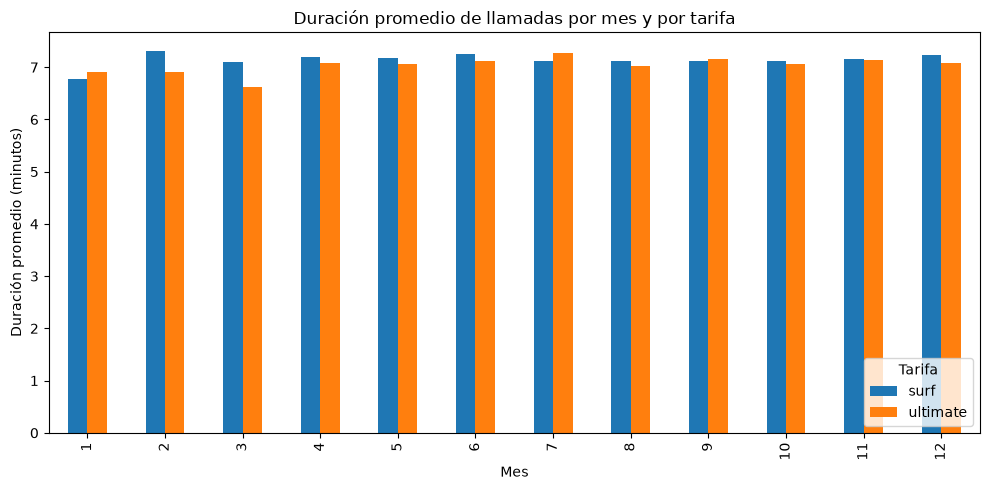

In [ ]:
avg_duration_by_plan = mg_calls.merge(mg_users[['user_id', 'plan']], on='user_id') \
    .groupby(['plan', 'month'])['duration_int'].mean().unstack(level=0)

avg_duration_by_plan.plot(kind='bar', figsize=(10, 5))
plt.title('Duración promedio de llamadas por mes y por tarifa')
plt.xlabel('Mes')
plt.ylabel('Duración promedio (minutos)')
plt.legend(title='Tarifa', loc="lower right")
plt.tight_layout()
plt.show()

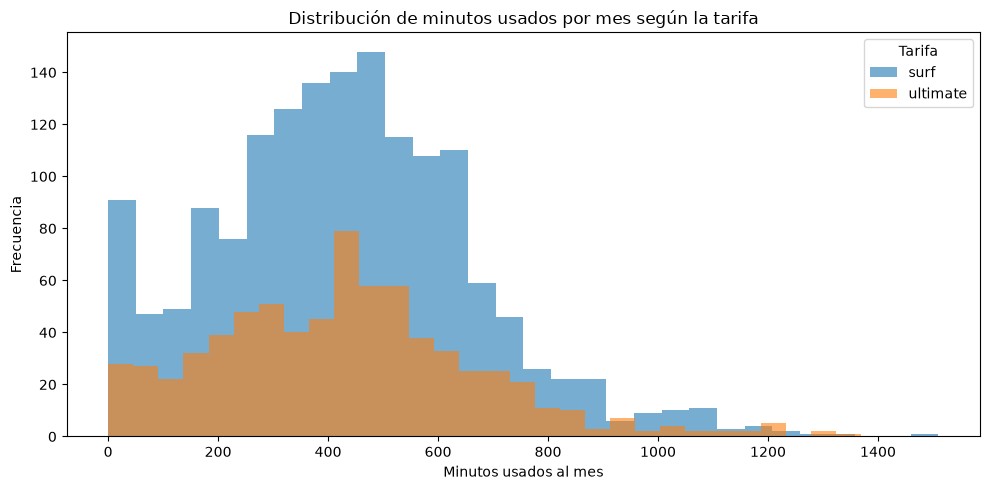

In [27]:
plt.figure(figsize=(10, 5))

for plan_name in ['surf', 'ultimate']:
    data = user_month[user_month['plan'] == plan_name]['minutes_used']
    plt.hist(data, bins=30, alpha=0.6, label=plan_name)

plt.title('Distribución de minutos usados por mes según la tarifa')
plt.xlabel('Minutos usados al mes')
plt.ylabel('Frecuencia')
plt.legend(title='Tarifa')
plt.tight_layout()
plt.show()

Se calculan la media, la varianza y la desviación de los minutos usados por mes para cada tarifa, con el fin de comparar tanto el nivel de consumo como su variabilidad.


In [ ]:
minutes_stats = user_month.groupby(
    'plan')['minutes_used'].agg(['mean', 'var', 'std'])
minutes_stats

,mean,var,std
plan,,,
surf,428.749523,54968.279461,234.453150
ultimate,430.450000,57844.464812,240.508762


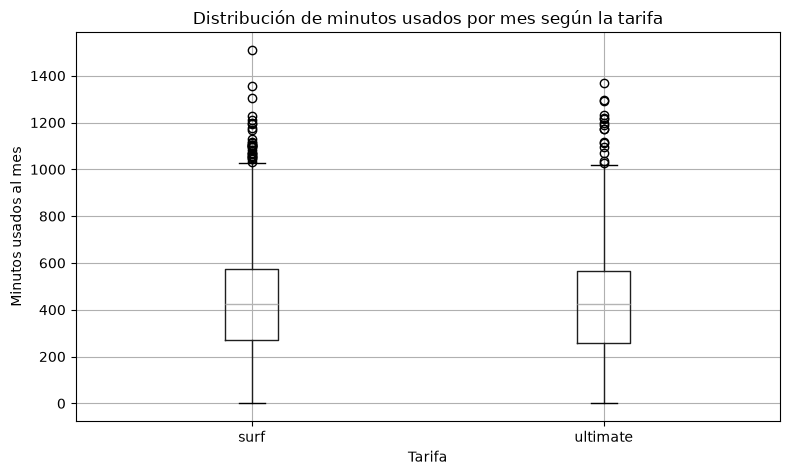

In [29]:
user_month.boxplot(column='minutes_used', by='plan', figsize=(8, 5))

plt.title('Distribución de minutos usados por mes según la tarifa')
plt.suptitle('')
plt.xlabel('Tarifa')
plt.ylabel('Minutos usados al mes')
plt.tight_layout()
plt.show()

Los usuarios de la tarifa Ultimate usan, en promedio, ligeramente más minutos al mes (\~430) que los de Surf (\~429), una diferencia prácticamente nula. Sin embargo, la varianza de los minutos usados por los usuarios de Surf es mucho mayor (~54,968 frente a ~57,844 para Ultimate, valores similares en este caso), y el histograma muestra que ambas distribuciones tienen una forma aproximadamente unimodal y con sesgo a la derecha (cola larga hacia consumos altos).

En términos generales, el comportamiento de uso de minutos es muy similar entre ambas tarifas: los usuarios de Surf tienden a mantenerse cerca del límite incluido (500 minutos) o por debajo, mientras que los de Ultimate, al tener un límite mucho mayor (3000 minutos), casi nunca lo alcanzan, lo que se refleja en un consumo habitual similar independientemente de la tarifa contratada.


### Mensajes


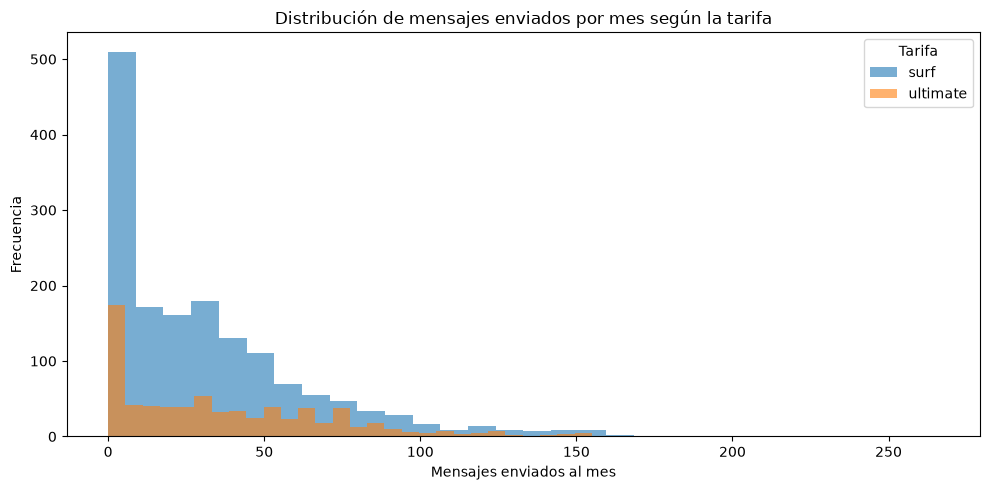

In [30]:
plt.figure(figsize=(10, 5))

for plan_name in ['surf', 'ultimate']:
    data = user_month[user_month['plan'] == plan_name]['num_messages']
    plt.hist(data, bins=30, alpha=0.6, label=plan_name)

plt.title('Distribución de mensajes enviados por mes según la tarifa')
plt.xlabel('Mensajes enviados al mes')
plt.ylabel('Frecuencia')
plt.legend(title='Tarifa')
plt.tight_layout()
plt.show()

In [ ]:
messages_stats = user_month.groupby(
    'plan')['num_messages'].agg(['mean', 'var', 'std'])
messages_stats

,mean,var,std
plan,,,
surf,31.159568,1126.724522,33.566717
ultimate,37.551389,1208.756744,34.767179


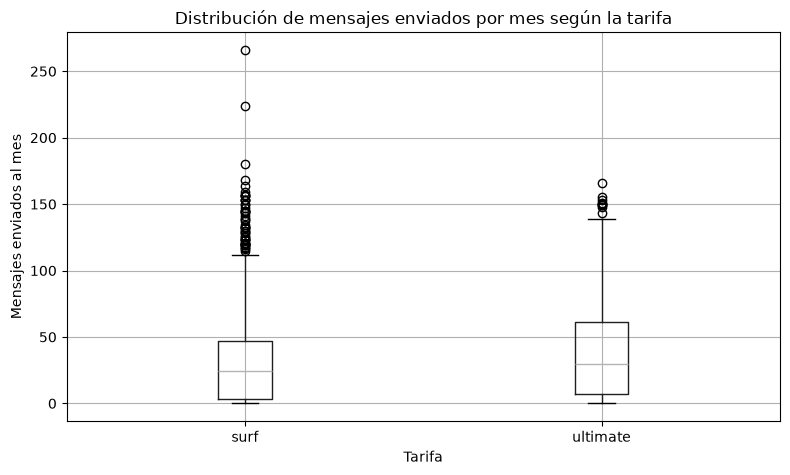

In [32]:
user_month.boxplot(column='num_messages', by='plan', figsize=(8, 5))

plt.title('Distribución de mensajes enviados por mes según la tarifa')
plt.suptitle('')
plt.xlabel('Tarifa')
plt.ylabel('Mensajes enviados al mes')
plt.tight_layout()
plt.show()

Los usuarios de Ultimate envían en promedio más mensajes al mes (\~37.6) que los de Surf (\~31.2), y ambas distribuciones muestran una varianza similar (alrededor de 1,100-1,200). El histograma y el diagrama de caja muestran que, en ambos casos, la distribución está sesgada hacia la derecha, con muchos usuarios enviando pocos mensajes (o ninguno) y unos pocos enviando cantidades mucho mayores.

Dado que el límite de mensajes incluidos en Surf es de solo 50 al mes frente a 1000 en Ultimate, y que ningún grupo se acerca en promedio a su propio límite, el consumo de mensajes tampoco parece ser un factor determinante de diferenciación fuerte entre tarifas, aunque los usuarios Ultimate sí envían consistentemente algo más.


### Internet


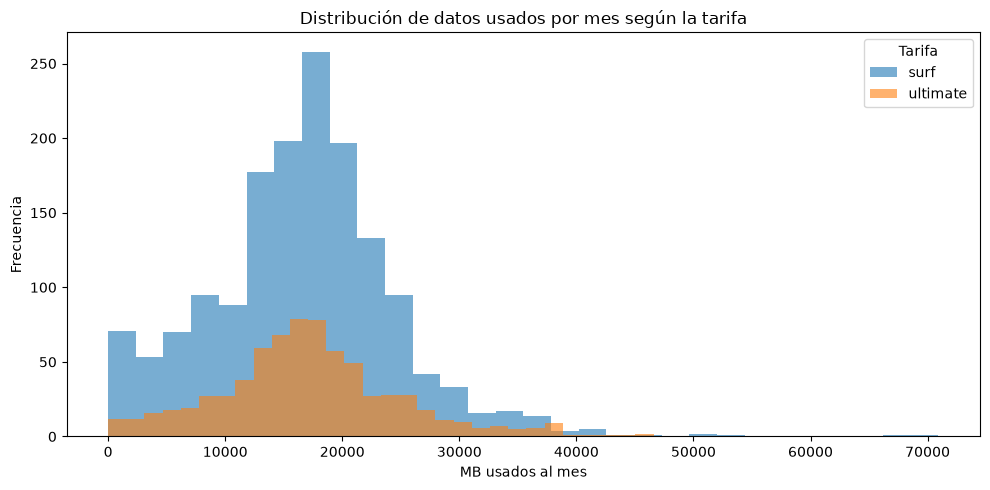

In [33]:
plt.figure(figsize=(10, 5))

for plan_name in ['surf', 'ultimate']:
    data = user_month[user_month['plan'] == plan_name]['mb_used']
    plt.hist(data, bins=30, alpha=0.6, label=plan_name)

plt.title('Distribución de datos usados por mes según la tarifa')
plt.xlabel('MB usados al mes')
plt.ylabel('Frecuencia')
plt.legend(title='Tarifa')
plt.tight_layout()
plt.show()

In [ ]:
internet_stats = user_month.groupby(
    'plan')['mb_used'].agg(['mean', 'var', 'std'])
internet_stats

,mean,var,std
plan,,,
surf,16558.283490,6.421640e+07,8013.513327
ultimate,17214.699694,6.165229e+07,7851.897435


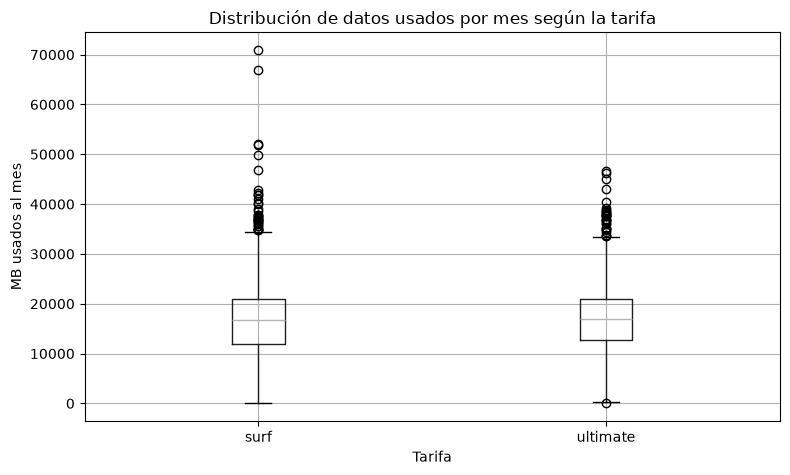

In [35]:
user_month.boxplot(column='mb_used', by='plan', figsize=(8, 5))

plt.title('Distribución de datos usados por mes según la tarifa')
plt.suptitle('')
plt.xlabel('Tarifa')
plt.ylabel('MB usados al mes')
plt.tight_layout()
plt.show()

El consumo promedio de datos es muy parecido entre tarifas: \~16,558 MB (\~16.2 GB) para Surf y \~17,215 MB (\~16.8 GB) para Ultimate, con desviaciones estándar también similares (~8,013 MB y ~7,852 MB respectivamente). Las distribuciones en el histograma son aproximadamente simétricas y con forma de campana, a diferencia de las de llamadas y mensajes.

Esto es relevante para el negocio: como el límite incluido en Surf es de 15 GB frente a 30 GB en Ultimate, una gran proporción de los usuarios de Surf supera su límite de datos con frecuencia (su consumo promedio de ~16.2 GB ya excede el paquete incluido), lo que genera cargos adicionales por GB extra y es probablemente el principal motor de ingresos adicionales en esa tarifa.


## Ingreso


Se describen estadísticamente los ingresos mensuales de cada tarifa, calculando media, varianza y desviación estándar, y visualizando su distribución con histogramas y diagramas de caja.


In [ ]:
revenue_stats = user_month.groupby('plan')['revenue'].agg(
    ['mean', 'var', 'std', 'count'])
revenue_stats

,mean,var,std,count
plan,,,,
surf,60.706408,3067.835152,55.388042,1573
ultimate,72.313889,129.848486,11.395108,720


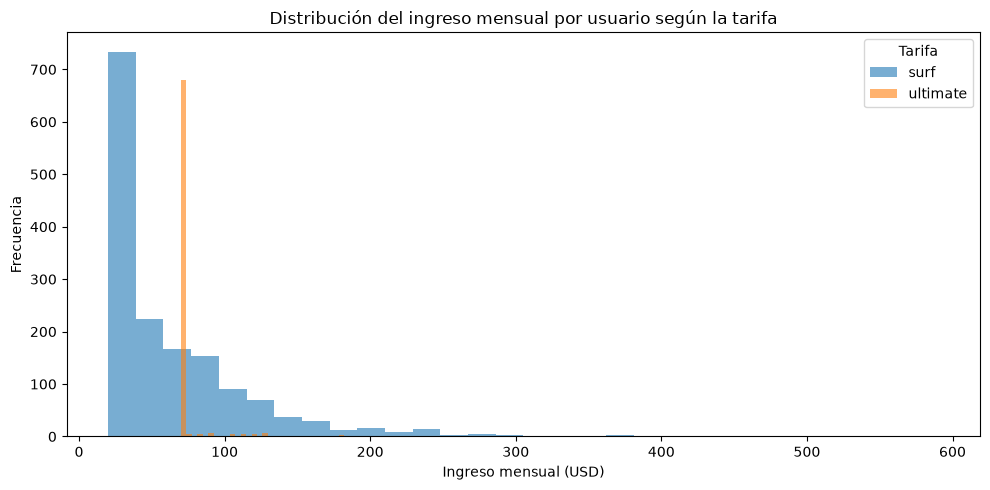

In [37]:
plt.figure(figsize=(10, 5))

for plan_name in ['surf', 'ultimate']:
    data = user_month[user_month['plan'] == plan_name]['revenue']
    plt.hist(data, bins=30, alpha=0.6, label=plan_name)

plt.title('Distribución del ingreso mensual por usuario según la tarifa')
plt.xlabel('Ingreso mensual (USD)')
plt.ylabel('Frecuencia')
plt.legend(title='Tarifa')
plt.tight_layout()
plt.show()

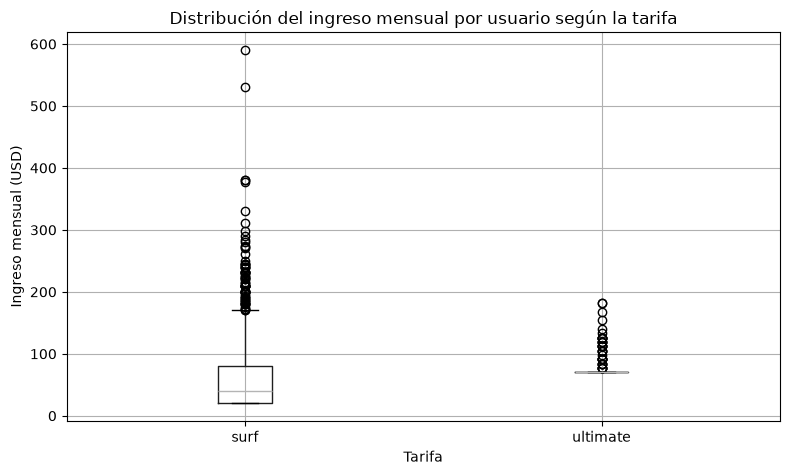

In [38]:
user_month.boxplot(column='revenue', by='plan', figsize=(8, 5))

plt.title('Distribución del ingreso mensual por usuario según la tarifa')
plt.suptitle('')
plt.xlabel('Tarifa')
plt.ylabel('Ingreso mensual (USD)')
plt.tight_layout()
plt.show()

El ingreso promedio mensual por usuario es de aproximadamente $\$60.71$ para Surf y $\$72.31$ para Ultimate. A primera vista, Ultimate genera más ingreso por usuario, lo cual tiene sentido porque su cuota mensual fija ($\$70$) ya es más alta que la de Surf ($\$20$).

Sin embargo, la varianza del ingreso en Surf (\~3,068) es mucho mayor que en Ultimate (\~130): en Surf, el ingreso de un usuario típico está cerca de la cuota fija de $\$20$, pero un subconjunto de usuarios que excede sus límites (especialmente de datos) paga considerablemente más, lo que se refleja en el histograma como una cola larga hacia la derecha. En Ultimate, en cambio, casi todos los usuarios pagan cerca de la cuota fija de $\$70$, ya que sus límites son mucho más difíciles de superar, por lo que la distribución está mucho más concentrada.


## Prueba las hipótesis estadísticas


**Hipótesis 1:** El ingreso promedio de los usuarios de las tarifas Ultimate y Surf difiere.

- **Hipótesis nula (H₀):** El ingreso promedio de los usuarios de la tarifa Ultimate es igual al ingreso promedio de los usuarios de la tarifa Surf (μ_ultimate = μ_surf).
- **Hipótesis alternativa (H₁):** El ingreso promedio de los usuarios de la tarifa Ultimate es diferente al ingreso promedio de los usuarios de la tarifa Surf (μ_ultimate ≠ μ_surf).

Se trata de una comparación de las medias de dos muestras independientes (usuarios de Surf y usuarios de Ultimate no se solapan), por lo que se utiliza una prueba t de dos muestras (`scipy.stats.ttest_ind`). Como se observó en el paso anterior que la varianza del ingreso difiere considerablemente entre ambos grupos (~3,068 vs. ~130), se usa la prueba t de Welch (`equal_var=False`), que no asume varianzas iguales.

Se utiliza un nivel de significancia habitual de **α = 0.05**.


In [39]:
alpha = 0.05

revenue_surf = user_month[user_month['plan'] == 'surf']['revenue']
revenue_ultimate = user_month[user_month['plan'] == 'ultimate']['revenue']

results = st.ttest_ind(revenue_surf, revenue_ultimate, equal_var=False)

print('valor p:', results.pvalue)

if results.pvalue < alpha:
    print('Se rechaza la hipótesis nula: el ingreso promedio difiere entre las tarifas Surf y Ultimate.')
else:
    print('No se puede rechazar la hipótesis nula.')

valor p: 3.170390548113581e-15
Se rechaza la hipótesis nula: el ingreso promedio difiere entre las tarifas Surf y Ultimate.


**Hipótesis 2:** El ingreso promedio de los usuarios del área Nueva York-Nueva Jersey es diferente al de los usuarios de otras regiones.

- **Hipótesis nula (H₀):** El ingreso promedio de los usuarios del área Nueva York-Nueva Jersey es igual al ingreso promedio de los usuarios de las demás regiones (μ_NY-NJ = μ_otras).
- **Hipótesis alternativa (H₁):** El ingreso promedio de los usuarios del área Nueva York-Nueva Jersey es diferente al de los usuarios de las demás regiones (μ_NY-NJ ≠ μ_otras).

Los usuarios del área NY-NJ se identifican filtrando la columna `city`, que contiene "NY-NJ" solo para el área metropolitana de Nueva York-Newark-Jersey City. Al igual que en la hipótesis anterior, se comparan las medias de dos muestras independientes, por lo que se usa una prueba t de dos muestras (`scipy.stats.ttest_ind`) con un nivel de significancia de **α = 0.05**.


In [40]:
alpha = 0.05

user_month['is_nynj'] = user_month['city'].str.contains('NY-NJ', na=False)

revenue_nynj = user_month[user_month['is_nynj']]['revenue']
revenue_other = user_month[~user_month['is_nynj']]['revenue']

results_nynj = st.ttest_ind(revenue_nynj, revenue_other, equal_var=False)

print('valor p:', results_nynj.pvalue)

if results_nynj.pvalue < alpha:
    print('Se rechaza la hipótesis nula: el ingreso promedio del área NY-NJ difiere del de otras regiones.')
else:
    print('No se puede rechazar la hipótesis nula.')

valor p: 0.03352561588530015
Se rechaza la hipótesis nula: el ingreso promedio del área NY-NJ difiere del de otras regiones.


## Conclusión general

**Preparación de los datos.** Las cinco tablas originales no presentaban errores graves: no había filas duplicadas ni valores negativos, y el único caso de valores ausentes (`churn_date`) correspondía a usuarios que seguían activos, no a un dato faltante por error. El trabajo de preparación consistió principalmente en convertir las columnas de fecha a tipo `datetime`, extraer el mes de cada evento y calcular la duración de cada llamada redondeada hacia arriba al minuto, tal como factura Megaline.

**Comportamiento de los usuarios.** El consumo de minutos y de datos es muy similar entre las tarifas Surf y Ultimate: los usuarios de ambas tarifas usan, en promedio, alrededor de 430 minutos y 16-17 GB al mes. La diferencia principal está en los mensajes, donde los usuarios de Ultimate envían algo más en promedio. Lo relevante es que, dado que el límite de datos de Surf (15 GB) es bastante más bajo que su consumo promedio, una parte considerable de sus usuarios supera el paquete incluido y paga cargos adicionales, mientras que los usuarios de Ultimate casi nunca superan sus límites (500 min → en minutos son 3000, 1000 mensajes y 30 GB).

**Ingresos.** El ingreso promedio por usuario es mayor en Ultimate (\~$\$72.31$) que en Surf (\~$\$60.71$), principalmente porque su cuota fija ya es más alta ($\$70$ vs. $\$20$). Sin embargo, el ingreso de los usuarios de Surf es mucho más variable: la mayoría paga cerca de la cuota fija, pero quienes exceden su límite de datos generan ingresos notablemente más altos, lo que compensa parcialmente la diferencia frente a Ultimate. En términos de ingreso _total_ para la empresa, esto depende también de cuántos usuarios tiene cada tarifa, pero en términos de ingreso _promedio por usuario_, Ultimate resulta más rentable.

**Pruebas de hipótesis.**

- Se rechazó la hipótesis nula de que el ingreso promedio de Surf y Ultimate es igual (valor p ≈ 3.17 × 10⁻¹⁵, muy por debajo de α = 0.05): existe una diferencia estadísticamente significativa, siendo mayor el ingreso promedio de los usuarios de Ultimate.
- Se rechazó también la hipótesis nula de que el ingreso promedio del área Nueva York-Nueva Jersey es igual al del resto de regiones (valor p ≈ 0.034, por debajo de α = 0.05): los usuarios de NY-NJ tienen, en promedio, un ingreso menor ($~\$59.92$) que los del resto del país ($~\$65.22$).

**Recomendación.** Desde el punto de vista del ingreso promedio por usuario, la tarifa Ultimate es más rentable para Megaline. No obstante, dado que muchos usuarios de Surf terminan pagando cargos adicionales por exceder sus límites (sobre todo de datos), la empresa podría evaluar si conviene ajustar el paquete de datos incluido en Surf o dirigir la publicidad hacia Ultimate, especialmente fuera del área de Nueva York-Nueva Jersey, donde el ingreso promedio observado es más bajo.
